# Calisma 2 - Kesitleri Video Gibi Isleyerek Pnomotoraks Segmentasyonu: SAM2 Bellek Tabanli Kesitler Arasi Yayilim

**Fikir (danisman onerisi):** Radyolog BT'yi okurken kesitler arasinda gezinir; kesitleri bir **video** gibi
ele alip SAM2'nin video bellegini (memory attention) kullanarak bir kesitteki pnomotoraks maskesini
komsu kesitlere tasiyabiliriz. Elimizdeki veri her hasta icin ~5 seyrek kesit oldugundan bu calisma
**seyrek kesit (sparse-slice) senaryosunda** iki soruyu yanitlar:

1. **Etiketleme verimliligi:** Uzman yalnizca **1 kesiti** isaretlerse (maske ya da sadece kutu), kalan kesitler ne kadar dogru bulunur?
   Etiketleme butcesi 1/2/3 kesit oldugunda dogruluk nasil degisir?
2. **Tam otomatik video modu:** U-Net'in en emin oldugu kesitten baslatilan yayilim, kesitleri bagimsiz isleyen
   ilk makale pipeline'ina gore daha tutarli/dogru mu? U-Net kanit kapisi (hibrit) yayilim kaymasini (drift) azaltir mi?

| Kod | Yontem | Uzman etkilesimi |
|---|---|---|
| B0 | Bagimsiz U-Net (her kesit ayri) | yok |
| B1 | Bagimsiz U-Net + SAM2 goruntu modu (ilk makale) | yok |
| B2 | Anahtar kesit GT maskesini diger kesitlere kopyala (alt sinir) | 1 kesit maske |
| P1 | SAM2 video: anahtar kesitte GT **maske** -> ileri+geri yayilim | 1 kesit maske |
| P2 | SAM2 video: anahtar kesitte GT **kutu** -> yayilim | 1 kesit kutu (cok ucuz) |
| P3 | SAM2 video: U-Net'in en emin oldugu kesitten **otomatik** baslatma | yok |
| P4 | P3 + U-Net kanit kapisi (hibrit) | yok |

Etiketli (anahtar) kesitler adil karsilastirma icin **degerlendirme disinda** tutulur.

**Sinirlilik:** Kesitler arasi mesafe (slice spacing) bilinmiyor; kesitler seriden aralikli secilmis olabilir.
Bu nedenle ardisik kesitler arasi goruntu benzerligi (korelasyon) olculup sonuclarla iliskilendirilir.
Tam seri (yuzlerce kesit) senaryosu **Calisma 3**'te acik veri ile test edilir.

In [ ]:
!pip install -q segmentation_models_pytorch opencv-python-headless pillow scipy matplotlib pandas scikit-learn
!rm -rf /content/sam2
!git clone -q https://github.com/facebookresearch/sam2.git /content/sam2
%cd /content/sam2
!SAM2_BUILD_CUDA=0 pip install -q -e .
!mkdir -p checkpoints
!wget -q -O /content/sam2/checkpoints/sam2.1_hiera_small.pt https://dl.fbaipublicfiles.com/segment_anything_2/092824/sam2.1_hiera_small.pt
%cd /content

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.8/154.8 kB 7.4 MB/s eta 0:00:00
/content/sam2
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.2/42.2 kB 2.1 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 168.8/168.8 kB 9.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 129.6/129.6 kB 13.6 MB/s eta 0:00:00
  Building editable for SAM-2 (pyproject.toml) ... done
/content


### Ortak yardimci modul
Asagidaki hucre `pnx_ortak.py` dosyasini Colab diskine yazar (ilk makaledeki fonksiyonlarin aynisi). Degistirmeniz gerekmez.

In [ ]:
%%writefile /content/pnx_ortak.py
# -*- coding: utf-8 -*-
"""
pnx_ortak.py - Uc yeni calismanin (Calisma 1/2/3) ortak yardimci modulu.

Pnomotoraks_sonuc3.ipynb notebook'undaki veri hazirlama, hasta bazli bolme,
U-Net cikarimi (sliding window), SAM2 sinir iyilestirme, birlestirme kurali,
guvenilirlik katsayisi ve metrik fonksiyonlarinin AYNISI buraya tasinmistir.
Boylece uc calisma da:
  * ayni egitilmis U-Net agirligini (pnomotoraks_unet.pth) yeniden egitmeden kullanir,
  * ayni tohumla (SEED=42) ayni train/val/test hasta bolmesini uretir
    (test hastalari ilk makaledekiyle birebir aynidir, sizinti olmaz),
  * ilk makaledeki pipeline'i "temel model" (baseline) olarak birebir yeniden uretir.

Colab'da kullanim:
    import sys; sys.path.insert(0, '/content/drive/MyDrive/pnx_kod')
    import pnx_ortak as po
    po.init_unet(); po.init_sam2_image()
"""
import os, glob, random, time
import numpy as np
import cv2
import torch
from PIL import Image
from scipy import ndimage

# ---------------------------------------------------------------------------
# Yapilandirma (ilk makaleyle ayni degerler)
# ---------------------------------------------------------------------------
RAW_DIR = '/content/drive/MyDrive/CT_goruntuler_anon'
DRIVE_BACKUP_DIR = '/content/drive/MyDrive/pnomotoraks_v3_artifacts'
UNET_WEIGHT_PATH = f'{DRIVE_BACKUP_DIR}/pnomotoraks_unet.pth'

SAM2_REPO_DIR = '/content/sam2'
SAM2_CHECKPOINT = '/content/sam2/checkpoints/sam2.1_hiera_small.pt'
SAM2_CONFIG = 'configs/sam2.1/sam2.1_hiera_s.yaml'

IMAGE_SIZE = 224
PATCH_STRIDE = 224
SEED = 42
PNEUMOTHORAX_LABEL = 1
LUNG_LABEL = 2
TRAIN_RATIO = 0.65
VAL_RATIO = 0.10

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'

unet_model = None
sam2_image_predictor = None
_sam2_base_model = None


def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


# ---------------------------------------------------------------------------
# Veri: hasta indeksi ve hasta bazli bolme (sonuc3 Hucre 4-5 ile birebir ayni)
# ---------------------------------------------------------------------------
def _slice_sort_key(path):
    stem = os.path.splitext(os.path.basename(path))[0]
    return (0, int(stem)) if stem.isdigit() else (1, stem)


def find_pairs_for_patient(patient_dir, numeric_order=False):
    # numeric_order=False: ilk makaledeki gibi alfabetik siralama (bolme ayni kalsin diye).
    # numeric_order=True : kesitleri sayisal sirada dondurur (video/sekans calismalari icin;
    #                      '10.jpg' '2.jpg'den once gelmesin).
    pairs = []
    jpg_files = sorted(glob.glob(os.path.join(patient_dir, '*.jpg')))
    if numeric_order:
        jpg_files = sorted(jpg_files, key=_slice_sort_key)
    for jpg_path in jpg_files:
        stem = os.path.splitext(os.path.basename(jpg_path))[0]
        png_path = os.path.join(patient_dir, stem + '.png')
        if os.path.exists(png_path):
            pairs.append((jpg_path, png_path))
    return pairs


def build_patient_split(raw_dir=RAW_DIR, seed=SEED, numeric_order=True):
    """Ilk makaledeki hasta bazli bolmeyi birebir yeniden uretir.

    Donus: patient_index {pid: [(jpg, png), ...]}, split_of_patient {pid: 'train'|'val'|'test'}
    """
    patient_dirs = sorted([d for d in glob.glob(os.path.join(raw_dir, '*')) if os.path.isdir(d)])
    patient_index = {}
    for pdir in patient_dirs:
        pid = os.path.basename(pdir)
        pairs = find_pairs_for_patient(pdir, numeric_order=numeric_order)
        if len(pairs) > 0:
            patient_index[pid] = pairs

    patient_ids = sorted(patient_index.keys())
    rng = random.Random(seed)
    rng.shuffle(patient_ids)
    n = len(patient_ids)
    n_train = int(round(n * TRAIN_RATIO))
    n_val = int(round(n * VAL_RATIO))
    split_of_patient = {}
    for pid in patient_ids[:n_train]:
        split_of_patient[pid] = 'train'
    for pid in patient_ids[n_train:n_train + n_val]:
        split_of_patient[pid] = 'val'
    for pid in patient_ids[n_train + n_val:]:
        split_of_patient[pid] = 'test'
    return patient_index, split_of_patient


def load_image_rgb(image_path):
    image = cv2.imread(image_path, cv2.IMREAD_COLOR)
    return cv2.cvtColor(image, cv2.COLOR_BGR2RGB)


def load_label_map(mask_path):
    m = np.array(Image.open(mask_path))
    if m.ndim == 3:
        m = m[..., 0]
    return m


def load_binary_mask(mask_path, label=PNEUMOTHORAX_LABEL):
    return (load_label_map(mask_path) == label).astype(np.uint8)


# ---------------------------------------------------------------------------
# Morfolojik yardimcilar ve rapor yardimcilari (sonuc3 Hucre 19)
# ---------------------------------------------------------------------------
def clean_mask(mask, min_area=80):
    mask = (mask > 0).astype(np.uint8)
    labeled, num = ndimage.label(mask)
    out = np.zeros_like(mask, dtype=np.uint8)
    for i in range(1, num + 1):
        region = (labeled == i)
        if region.sum() >= min_area:
            out[region] = 1
    return out


def largest_component(mask):
    labeled, num = ndimage.label(mask)
    if num == 0:
        return mask.astype(np.uint8)
    sizes = ndimage.sum(mask, labeled, range(1, num + 1))
    return (labeled == (int(np.argmax(sizes)) + 1)).astype(np.uint8)


def area_ratio(mask):
    return float(mask.sum() / mask.size)


def estimate_side(mask, radiological_convention=True):
    """Pnomotoraksin tarafini tahmin eder.

    DIKKAT: Aksiyel BT goruntuleri radyolojik konvansiyonda gosterilir; goruntunun
    SOL yarisi hastanin SAG tarafidir. Ilk makaledeki kodda (sonuc3) goruntunun sol
    yarisi 'sol' olarak etiketleniyordu (radyolojik konvansiyon dikkate alinmamisti).
    Yeni calismalarda varsayilan olarak radyolojik konvansiyon kullanilir; ilk
    makaleyle birebir karsilastirma gerekirse radiological_convention=False verin.
    """
    if mask.sum() == 0:
        return 'belirgin degil'
    h, w = mask.shape
    img_left = mask[:, :w // 2].sum()
    img_right = mask[:, w // 2:].sum()
    if radiological_convention:
        side_of_img_left, side_of_img_right = 'sag', 'sol'
    else:
        side_of_img_left, side_of_img_right = 'sol', 'sag'
    if img_left > img_right * 1.2:
        return side_of_img_left
    elif img_right > img_left * 1.2:
        return side_of_img_right
    return 'bilateral'


def estimate_extent(mask):
    r = area_ratio(mask)
    if r < 0.005:
        return 'cok kucuk'
    elif r < 0.02:
        return 'kucuk'
    elif r < 0.06:
        return 'orta'
    return 'genis'


def make_overlay(image_np, mask, color=(255, 0, 0), alpha=0.35):
    overlay = image_np.copy()
    m = mask.astype(bool)
    col = np.array(color, dtype=np.float32)
    overlay[m] = ((1 - alpha) * overlay[m] + alpha * col).astype(np.uint8)
    return overlay


def mask_iou(mask_a, mask_b):
    inter = np.logical_and(mask_a > 0, mask_b > 0).sum()
    union = np.logical_or(mask_a > 0, mask_b > 0).sum()
    return 0.0 if union == 0 else float(inter) / float(union)


def mask_box(mask, margin=10):
    h, w = mask.shape
    ys, xs = np.where(mask > 0)
    return np.array([max(0, xs.min() - margin), max(0, ys.min() - margin),
                     min(w - 1, xs.max() + margin), min(h - 1, ys.max() + margin)])


# ---------------------------------------------------------------------------
# Metrikler (sonuc3 Hucre 12)
# ---------------------------------------------------------------------------
def segmentation_metrics(pred_mask, gt_mask, eps=1e-6):
    p = pred_mask.flatten().astype(np.uint8)
    g = gt_mask.flatten().astype(np.uint8)
    tp = int(np.sum((p == 1) & (g == 1)))
    tn = int(np.sum((p == 0) & (g == 0)))
    fp = int(np.sum((p == 1) & (g == 0)))
    fn = int(np.sum((p == 0) & (g == 1)))
    sens = (tp + eps) / (tp + fn + eps)
    prec = (tp + eps) / (tp + fp + eps)
    return {
        'dice': (2 * tp + eps) / (2 * tp + fp + fn + eps),
        'iou': (tp + eps) / (tp + fp + fn + eps),
        'accuracy': (tp + tn + eps) / (tp + tn + fp + fn + eps),
        'sensitivity': sens,
        'specificity': (tn + eps) / (tn + fp + eps),
        'precision': prec,
        'f1': (2 * prec * sens + eps) / (prec + sens + eps),
    }


def hd95_pixels(pred_mask, gt_mask):
    pred_mask = (pred_mask > 0).astype(np.uint8)
    gt_mask = (gt_mask > 0).astype(np.uint8)
    if pred_mask.sum() == 0 or gt_mask.sum() == 0:
        return float('nan')
    pb = pred_mask - ndimage.binary_erosion(pred_mask).astype(np.uint8)
    gb = gt_mask - ndimage.binary_erosion(gt_mask).astype(np.uint8)
    if pb.sum() == 0 or gb.sum() == 0:
        return float('nan')
    gt_dt = ndimage.distance_transform_edt(1 - gb)
    pr_dt = ndimage.distance_transform_edt(1 - pb)
    return float(max(np.percentile(gt_dt[pb > 0], 95), np.percentile(pr_dt[gb > 0], 95)))


def hemithorax_counts(pred_mask, gt_mask, min_pixels=50):
    """Yari-toraks (goruntunun sol/sag yarisi) duzeyinde tespit sayimlari.

    Veri setindeki kesitlerin neredeyse tamami pnomotoraks pozitiftir (852/853), bu yuzden kesit
    duzeyinde ozgulluk olculemez. Pnomotoraks cogunlukla tek tarafli oldugundan, GT'de pnomotoraks
    olmayan karsi yari-toraks dogal bir negatif ornektir; burada tahmin edilen maske varsa yanlis pozitiftir.
    Donus: {'tp','fn','tn','fp'} (iki yari uzerinden toplam)."""
    w = gt_mask.shape[1]
    c = {'tp': 0, 'fn': 0, 'tn': 0, 'fp': 0}
    for sl in (slice(0, w // 2), slice(w // 2, w)):
        g = gt_mask[:, sl].sum() >= min_pixels
        p = pred_mask[:, sl].sum() >= min_pixels
        c['tp' if g and p else 'fn' if g else 'fp' if p else 'tn'] += 1
    return c


def dice_3d(pred_vol, gt_vol, eps=1e-6):
    p = pred_vol > 0
    g = gt_vol > 0
    inter = np.logical_and(p, g).sum()
    return float((2 * inter + eps) / (p.sum() + g.sum() + eps))


def bootstrap_ci(values, n_boot=2000, alpha=0.05, seed=SEED):
    values = np.asarray([v for v in values if not np.isnan(v)])
    if len(values) == 0:
        return float('nan'), float('nan'), float('nan')
    rng = np.random.default_rng(seed)
    means = [rng.choice(values, len(values), replace=True).mean() for _ in range(n_boot)]
    return float(values.mean()), float(np.percentile(means, 100 * alpha / 2)), float(np.percentile(means, 100 * (1 - alpha / 2)))


# ---------------------------------------------------------------------------
# U-Net (sonuc3 Hucre 11 + 19)
# ---------------------------------------------------------------------------
def init_unet(weight_path=UNET_WEIGHT_PATH):
    global unet_model
    import segmentation_models_pytorch as smp
    unet_model = smp.Unet(encoder_name='mobilenet_v2', encoder_weights=None,
                          in_channels=3, classes=1, activation=None).to(DEVICE)
    unet_model.load_state_dict(torch.load(weight_path, map_location=DEVICE))
    unet_model.eval()
    print('U-Net yuklendi:', weight_path)
    return unet_model


_MEAN = np.array([0.485, 0.456, 0.406], dtype=np.float32)
_STD = np.array([0.229, 0.224, 0.225], dtype=np.float32)


def _to_tensor(patch_rgb):
    x = (patch_rgb.astype(np.float32) / 255.0 - _MEAN) / _STD
    return torch.from_numpy(x.transpose(2, 0, 1)).unsqueeze(0)


@torch.no_grad()
def unet_prob_map(image_np, patch_size=IMAGE_SIZE, stride=PATCH_STRIDE, batch_size=16):
    """Kaydirmali pencere ile tam goruntu olasilik haritasi (HxW, 0-1)."""
    h, w = image_np.shape[:2]
    ys = [0] if h <= patch_size else sorted(set(list(range(0, h - patch_size, stride)) + [h - patch_size]))
    xs = [0] if w <= patch_size else sorted(set(list(range(0, w - patch_size, stride)) + [w - patch_size]))
    prob_map = np.zeros((h, w), dtype=np.float32)
    count_map = np.zeros((h, w), dtype=np.float32)
    coords, tensors = [], []
    for y in ys:
        for x in xs:
            patch = image_np[y:y + patch_size, x:x + patch_size]
            ph, pw = patch.shape[:2]
            if ph < patch_size or pw < patch_size:
                patch = cv2.copyMakeBorder(patch, 0, patch_size - ph, 0, patch_size - pw, cv2.BORDER_CONSTANT, value=0)
            coords.append((y, x, ph, pw))
            tensors.append(_to_tensor(patch))
    for i in range(0, len(tensors), batch_size):
        batch = torch.cat(tensors[i:i + batch_size]).to(DEVICE)
        probs = torch.sigmoid(unet_model(batch))[:, 0].cpu().numpy()
        for (y, x, ph, pw), pr in zip(coords[i:i + batch_size], probs):
            prob_map[y:y + ph, x:x + pw] += pr[:ph, :pw]
            count_map[y:y + ph, x:x + pw] += 1.0
    count_map[count_map == 0] = 1.0
    return prob_map / count_map


def unet_predict(image_np, threshold=0.5):
    """sonuc3'teki unet_predict_external ile ayni cikti: (maske, guven, olasilik haritasi)."""
    prob = unet_prob_map(image_np)
    mask = largest_component(clean_mask((prob > threshold).astype(np.uint8)))
    return mask, float(prob.max()), prob


# ---------------------------------------------------------------------------
# SAM2 (goruntu modu; sonuc3 Hucre 18-19)
# ---------------------------------------------------------------------------
def _sam2_import():
    import sys
    if SAM2_REPO_DIR not in sys.path:
        sys.path.insert(0, SAM2_REPO_DIR)


def init_sam2_image():
    global sam2_image_predictor, _sam2_base_model
    _sam2_import()
    from sam2.build_sam import build_sam2
    from sam2.sam2_image_predictor import SAM2ImagePredictor
    _sam2_base_model = build_sam2(config_file=SAM2_CONFIG, ckpt_path=SAM2_CHECKPOINT, device=DEVICE)
    sam2_image_predictor = SAM2ImagePredictor(_sam2_base_model)
    print('SAM2 (goruntu modu) hazir.')
    return sam2_image_predictor


def init_sam2_video(offload_video_to_cpu=False):
    _sam2_import()
    from sam2.build_sam import build_sam2_video_predictor
    vp = build_sam2_video_predictor(SAM2_CONFIG, SAM2_CHECKPOINT, device=DEVICE)
    print('SAM2 (video modu) hazir.')
    return vp


@torch.no_grad()
def sam2_set_image(image_np):
    sam2_image_predictor.set_image(image_np)


@torch.no_grad()
def sam2_predict(image_np, unet_mask, prompt_type='box', box_margin=10, multimask_select='score',
                 image_already_set=False):
    """SAM2 goruntu modu tahmini.

    prompt_type: 'box' | 'point' | 'box+point'
    multimask_select: 'score' (ilk makaledeki gibi en yuksek SAM skoru) |
                      'agreement' (U-Net maskesiyle en yuksek IoU'lu aday)
    """
    if not image_already_set:
        sam2_image_predictor.set_image(image_np)
    h, w = image_np.shape[:2]
    has_mask = unet_mask.sum() > 0
    box = mask_box(unet_mask, box_margin) if has_mask else np.array([int(w * .05), int(h * .05), int(w * .95), int(h * .95)])
    if has_mask:
        ys, xs = np.where(unet_mask > 0)
        # Agirlik merkezi maskenin disina dusebilir (hilal seklindeki pnomotoraks);
        # bu yuzden maske icinde merkeze en yakin piksel kullanilir.
        cy, cx = ys.mean(), xs.mean()
        j = int(np.argmin((ys - cy) ** 2 + (xs - cx) ** 2))
        point = np.array([[int(xs[j]), int(ys[j])]])
    else:
        point = np.array([[w // 2, h // 2]])

    kwargs = dict(multimask_output=True)
    if prompt_type == 'box':
        kwargs.update(point_coords=None, point_labels=None, box=box)
    elif prompt_type == 'point':
        kwargs.update(point_coords=point, point_labels=np.array([1]), box=None)
    else:
        kwargs.update(point_coords=point, point_labels=np.array([1]), box=box)
    masks, scores, _ = sam2_image_predictor.predict(**kwargs)

    cands = [largest_component(clean_mask(m.astype(np.uint8))) for m in masks]
    if multimask_select == 'agreement' and has_mask:
        best = int(np.argmax([mask_iou(c, unet_mask) for c in cands]))
    else:
        best = int(np.argmax(scores))
    return cands[best], float(scores[best])


def combine_masks(unet_mask, sam_mask, min_agreement_iou=0.3):
    # sonuc3 Hucre 19 ile ayni kural: U-Net negatifse bos; uyum dusukse U-Net'e geri dus.
    if unet_mask.sum() == 0:
        return np.zeros_like(sam_mask, dtype=np.uint8)
    if mask_iou(unet_mask, sam_mask) < min_agreement_iou:
        return largest_component(clean_mask(unet_mask))
    return largest_component(clean_mask(np.logical_or(unet_mask > 0, sam_mask > 0).astype(np.uint8)))


def compute_reliability(unet_conf, sam_conf, final_mask, wU=0.35, wS=0.45, wA=0.20):
    area_term = min(area_ratio(final_mask) / 0.03, 1.0)
    return float(max(0.0, min(1.0, wU * unet_conf + wS * sam_conf + wA * area_term)))


def baseline_pipeline(image_np):
    """Ilk makaledeki (Biomedicines) tek gecisli pipeline: U-Net -> SAM2 kutu -> birlestirme."""
    t0 = time.time()
    unet_mask, unet_conf, prob = unet_predict(image_np)
    sam_mask, sam_conf = sam2_predict(image_np, unet_mask, prompt_type='box', box_margin=10)
    final = combine_masks(unet_mask, sam_mask)
    return {
        'mask': final, 'unet_mask': unet_mask, 'sam_mask': sam_mask,
        'unet_conf': unet_conf, 'sam_conf': sam_conf, 'prob': prob,
        'reliability': compute_reliability(unet_conf, sam_conf, final),
        'time_s': time.time() - t0,
    }


# ---------------------------------------------------------------------------
# Anatomik olabilirlik yardimcilari (Calisma 1 dogrulama ajani icin)
# ---------------------------------------------------------------------------
def body_mask(image_np, thr=20):
    """Govde (vucut) maskesi: goruntu esiklenir, en buyuk bilesen alinir, delikleri doldurulur.
    Pnomotoraks havasi govde ICINDE, hasta disindaki hava govde DISINDA kalir."""
    gray = cv2.cvtColor(image_np, cv2.COLOR_RGB2GRAY) if image_np.ndim == 3 else image_np
    m = (gray > thr).astype(np.uint8)
    m = cv2.morphologyEx(m, cv2.MORPH_CLOSE, np.ones((15, 15), np.uint8))
    m = largest_component(m)
    return ndimage.binary_fill_holes(m).astype(np.uint8)


def mean_intensity_in_mask(image_np, mask):
    gray = cv2.cvtColor(image_np, cv2.COLOR_RGB2GRAY) if image_np.ndim == 3 else image_np
    return float(gray[mask > 0].mean()) if mask.sum() > 0 else float('nan')


# ---------------------------------------------------------------------------
# VLM (Qwen2-VL; sonuc3 Hucre 30-31)
# ---------------------------------------------------------------------------
vlm_model = None
vlm_processor = None
VLM_MODEL_ID = 'Qwen/Qwen2-VL-2B-Instruct'


def init_vlm(model_id=VLM_MODEL_ID):
    global vlm_model, vlm_processor, VLM_MODEL_ID
    from transformers import Qwen2VLForConditionalGeneration, AutoProcessor
    VLM_MODEL_ID = model_id
    vlm_model = Qwen2VLForConditionalGeneration.from_pretrained(model_id, torch_dtype=torch.float16, device_map='auto')
    vlm_processor = AutoProcessor.from_pretrained(model_id)
    print('VLM hazir:', model_id)


@torch.no_grad()
def vlm_generate(image_pil, prompt_text, max_new_tokens=400, temperature=0.6, seed=None):
    from qwen_vl_utils import process_vision_info
    if seed is not None:
        torch.manual_seed(seed)
    messages = [{'role': 'user', 'content': [{'type': 'image', 'image': image_pil}, {'type': 'text', 'text': prompt_text}]}]
    chat = vlm_processor.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
    image_inputs, video_inputs = process_vision_info(messages)
    inputs = vlm_processor(text=[chat], images=image_inputs, videos=video_inputs, padding=True, return_tensors='pt').to(DEVICE)
    out = vlm_model.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=True,
                             temperature=temperature, top_p=0.9, repetition_penalty=1.3)
    trimmed = [o[len(i):] for i, o in zip(inputs.input_ids, out)]
    return vlm_processor.batch_decode(trimmed, skip_special_tokens=True, clean_up_tokenization_spaces=False)[0].strip()

Writing /content/pnx_ortak.py


In [ ]:
import os, sys, json, time, shutil
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from scipy import ndimage, stats

from google.colab import drive
drive.mount('/content/drive')
sys.path.insert(0, '/content')
import pnx_ortak as po

po.set_seed()
OUT_DIR = '/content/drive/MyDrive/pnx_calisma2'
FRAME_ROOT = '/content/pnx_frames'
os.makedirs(OUT_DIR, exist_ok=True)

patient_index, split_of_patient = po.build_patient_split(numeric_order=True)  # kesitler sayisal sirada
val_patients = sorted([p for p, s in split_of_patient.items() if s == 'val'])
test_patients = sorted([p for p, s in split_of_patient.items() if s == 'test'])
print(f'val: {len(val_patients)}  test: {len(test_patients)} hasta')

po.init_unet()
po.init_sam2_image()
video_predictor = po.init_sam2_video()

Mounted at /content/drive
val: 17  test: 43 hasta
U-Net yuklendi: /content/drive/MyDrive/pnomotoraks_v3_artifacts/pnomotoraks_unet.pth
SAM2 (goruntu modu) hazir.
SAM2 (video modu) hazir.


## 1. Veri: her hastanin kesitlerini "video kareleri" olarak hazirla + kesitler arasi benzerlik

In [ ]:
def hasta_verisi(pid):
    imgs, gts = [], []
    for jpg, png in patient_index[pid]:
        imgs.append(po.load_image_rgb(jpg))
        gts.append(po.load_binary_mask(png))
    return imgs, gts


def kareleri_yaz(pid, imgs):
    d = os.path.join(FRAME_ROOT, pid)
    shutil.rmtree(d, ignore_errors=True)
    os.makedirs(d)
    for i, im in enumerate(imgs):   # SAM2, kare adlarinin tamsayi olmasini bekler (00000.jpg ...)
        cv2.imwrite(os.path.join(d, f'{i:05d}.jpg'), cv2.cvtColor(im, cv2.COLOR_RGB2BGR), [cv2.IMWRITE_JPEG_QUALITY, 100])
    return d


def goruntu_korelasyonu(a, b):
    a = a[..., 0].astype(np.float32).ravel(); b = b[..., 0].astype(np.float32).ravel()
    return float(np.corrcoef(a, b)[0, 1])


VERI = {}
kor_rows = []
for pid in val_patients + test_patients:
    imgs, gts = hasta_verisi(pid)
    VERI[pid] = {'imgs': imgs, 'gts': gts, 'dir': kareleri_yaz(pid, imgs)}
    for i in range(len(imgs) - 1):
        kor_rows.append({'patient_id': pid, 'i': i, 'kor': goruntu_korelasyonu(imgs[i], imgs[i + 1]),
                         'gt_iou_ardisik': po.mask_iou(gts[i], gts[i + 1]) if (gts[i].sum() + gts[i + 1].sum()) > 0 else np.nan})
kor_df = pd.DataFrame(kor_rows)
kor_df.to_csv(f'{OUT_DIR}/ardisik_kesit_benzerligi.csv', index=False)
print('Ardisik kesit goruntu korelasyonu: ort=%.3f  medyan=%.3f  min=%.3f' % (kor_df.kor.mean(), kor_df.kor.median(), kor_df.kor.min()))
print('Ardisik kesit GT maske IoU (pozitif ciftler): ort=%.3f' % kor_df.gt_iou_ardisik.mean())

Ardisik kesit goruntu korelasyonu: ort=0.869  medyan=0.891  min=0.360
Ardisik kesit GT maske IoU (pozitif ciftler): ort=0.248


## 2. SAM2 video yayilimi (ileri + geri)

In [ ]:
@torch.inference_mode()
def video_yayilim(frame_dir, n_frames, istemler):
    """istemler: [{'frame': k, 'mask': HxW} veya {'frame': k, 'box': [x1,y1,x2,y2]}]
    Donus: n_frames uzunlugunda maske listesi, kare basi sure (s)."""
    t0 = time.time()
    state = video_predictor.init_state(video_path=frame_dir)
    video_predictor.reset_state(state)
    for ist in istemler:
        if 'mask' in ist:
            video_predictor.add_new_mask(inference_state=state, frame_idx=ist['frame'], obj_id=1, mask=ist['mask'].astype(bool))
        else:
            video_predictor.add_new_points_or_box(inference_state=state, frame_idx=ist['frame'], obj_id=1,
                                                  box=np.array(ist['box'], dtype=np.float32))
    t1 = time.time()
    maskeler = [None] * n_frames
    k0 = min(i['frame'] for i in istemler)
    for fi, _, logits in video_predictor.propagate_in_video(state):
        maskeler[fi] = (logits[0, 0] > 0).cpu().numpy().astype(np.uint8)
    for fi, _, logits in video_predictor.propagate_in_video(state, start_frame_idx=k0, reverse=True):
        if maskeler[fi] is None or fi < k0:
            maskeler[fi] = (logits[0, 0] > 0).cpu().numpy().astype(np.uint8)
    maskeler = [po.clean_mask(m) if m is not None else None for m in maskeler]
    video_predictor.reset_state(state)
    return maskeler, (time.time() - t1) / n_frames, t1 - t0


def anahtar_kesitler(gts, butce):
    """Uzmanin isaretleyecegi kesitler: once en buyuk GT alanli kesit, sonra ondan en uzak pozitif kesitler."""
    alan = [g.sum() for g in gts]
    poz = [i for i, a in enumerate(alan) if a > 0]
    if not poz:
        return []
    secim = [int(np.argmax(alan))]
    while len(secim) < min(butce, len(poz)):
        kalan = [i for i in poz if i not in secim]
        secim.append(max(kalan, key=lambda i: min(abs(i - s) for s in secim)))
    return sorted(secim)

## 3. Yontemlerin calistirilmasi

In [ ]:
def bagimsiz(pid):
    imgs = VERI[pid]['imgs']
    out = {'B0': [], 'B1': [], 'prob': [], 'conf': [], 't_B1': []}
    for im in imgs:
        r = po.baseline_pipeline(im)
        out['B0'].append(r['unet_mask']); out['B1'].append(r['mask'])
        out['prob'].append(r['prob']); out['conf'].append(r['unet_conf']); out['t_B1'].append(r['time_s'])
    return out


def kanit_kapisi(prop_mask, prob, unet_mask, tau):
    """P4: yayilan maskenin her bagli bileseni, icindeki ortalama U-Net olasiligi >= tau ise tutulur;
    yayilimla ortusen U-Net bilesenleri eklenir. Yayilim kaymasindan (drift) kaynakli yanlis pozitifleri azaltir."""
    if prop_mask is None or prop_mask.sum() == 0:
        return np.zeros_like(unet_mask)
    lab, n = ndimage.label(prop_mask)
    out = np.zeros_like(prop_mask)
    for j in range(1, n + 1):
        reg = lab == j
        if prob[reg].mean() >= tau:
            out[reg] = 1
    if unet_mask.sum() > 0 and po.mask_iou(unet_mask, prop_mask) > 0:
        out = np.logical_or(out, unet_mask).astype(np.uint8)
    return po.clean_mask(out)


def hasta_calistir(pid, butceler=(1, 2, 3), taus=(0.3,)):
    imgs, gts, d = VERI[pid]['imgs'], VERI[pid]['gts'], VERI[pid]['dir']
    n = len(imgs)
    b = bagimsiz(pid)
    sonuc = {'B0': b['B0'], 'B1': b['B1'], '_prob': b['prob'], '_sure': {'B1': float(np.mean(b['t_B1']))}, '_anahtar': {}}

    # --- Uzman etkilesimli modlar (yalnizca en az bir pozitif kesit varsa) ---
    for butce in butceler:
        ks = anahtar_kesitler(gts, butce)
        if len(ks) < butce:
            continue
        sonuc['_anahtar'][butce] = ks
        istem_m = [{'frame': k, 'mask': gts[k]} for k in ks]
        istem_b = [{'frame': k, 'box': po.mask_box(gts[k], margin=5)} for k in ks]
        sonuc[f'P1_b{butce}'], t_p, _ = video_yayilim(d, n, istem_m)
        sonuc['_sure'][f'P1_b{butce}'] = t_p
        sonuc[f'P2_b{butce}'], _, _ = video_yayilim(d, n, istem_b)
        # B2: her kesite en yakin etiketli kesitin maskesini kopyala
        sonuc[f'B2_b{butce}'] = [gts[min(ks, key=lambda k: abs(k - i))].copy() for i in range(n)]

    # --- Tam otomatik video modu ---
    adaylar = [i for i in range(n) if b['B0'][i].sum() > 0]
    if adaylar:
        k = max(adaylar, key=lambda i: b['conf'][i])
        sonuc['_anahtar']['oto'] = [k]
        p3, t_p3, _ = video_yayilim(d, n, [{'frame': k, 'mask': b['B1'][k]}])
        p3[k] = b['B1'][k]
        sonuc['P3'] = p3
        sonuc['_sure']['P3'] = t_p3
        for tau in taus:
            sonuc[f'P4_t{tau}'] = [b['B1'][i] if i == k else kanit_kapisi(p3[i], b['prob'][i], b['B0'][i], tau) for i in range(n)]
    else:
        bos = [np.zeros_like(gts[0]) for _ in range(n)]
        sonuc['P3'] = bos
        for tau in taus:
            sonuc[f'P4_t{tau}'] = bos
    return sonuc


def satirlar(pid, sonuc):
    gts, imgs = VERI[pid]['gts'], VERI[pid]['imgs']
    rows = []
    for yontem, maskeler in sonuc.items():
        if yontem.startswith('_'):
            continue
        butce = int(yontem.split('_b')[1]) if '_b' in yontem else None
        ks = sonuc['_anahtar'].get(butce, []) if butce else []
        oto_k = sonuc['_anahtar'].get('oto', [None])[0]
        for i, (m, g) in enumerate(zip(maskeler, gts)):
            m = m if m is not None else np.zeros_like(g)
            met = po.segmentation_metrics(m, g)
            # en yakin uzman etiketli kesite uzaklik ve goruntu benzerligi
            ref = min(ks, key=lambda k: abs(k - i)) if ks else None
            rows.append({'patient_id': pid, 'yontem': yontem, 'butce': butce, 'kesit': i,
                         'etiketli_kesit': i in ks, 'oto_anahtar': (i == oto_k),
                         'uzaklik': abs(i - ref) if ref is not None else np.nan,
                         'anahtar_kor': goruntu_korelasyonu(imgs[i], imgs[ref]) if ref is not None else np.nan,
                         'gt_pos': bool(g.sum() > 0), 'pred_pos': bool(m.sum() > 0),
                         'dice': met['dice'], 'iou': met['iou'], 'sensitivity': met['sensitivity'],
                         'precision': met['precision'], 'hd95_px': po.hd95_pixels(m, g),
                         **{'yt_' + k: v for k, v in po.hemithorax_counts(m, g).items()}})
    return rows

## 4. Val setinde P4 kanit kapisi esiginin (tau) secimi

In [ ]:
TAU_GRID = (0.05, 0.1, 0.2, 0.3, 0.4, 0.5)
val_rows = []
for pid in val_patients:
    val_rows += satirlar(pid, hasta_calistir(pid, butceler=(), taus=TAU_GRID))
val_res = pd.DataFrame(val_rows)
p4 = val_res[val_res.yontem.str.startswith('P4') & ~val_res.oto_anahtar]
# Hedef: pozitif kesit Dice'i ile karsi yari-toraksta yanlis pozitif oraninin dengesi
# (veride negatif kesit neredeyse yok; negatif ornek = GT'de pnomotoraks olmayan yari-toraks)
secim = p4.groupby('yontem').apply(lambda g: g[g.gt_pos].dice.mean() - g.yt_fp.sum() / max(g.yt_fp.sum() + g.yt_tn.sum(), 1))
print(secim.sort_values(ascending=False))
EN_IYI_TAU = float(secim.idxmax().split('_t')[1])
json.dump({'tau': EN_IYI_TAU, 'secim': secim.to_dict()}, open(f'{OUT_DIR}/val_tau_secimi.json', 'w'), indent=2)
print('Secilen tau:', EN_IYI_TAU)

frame loading (JPEG): 100%|██████████| 5/5 [00:01<00:00,  3.09it/s]
/content/sam2/sam2/sam2_video_predictor.py:786: UserWarning: cannot import name '_C' from 'sam2' (/content/sam2/sam2/__init__.py)

Skipping the post-processing step due to the error above. You can still use SAM 2 and it's OK to ignore the error above, although some post-processing functionality may be limited (which doesn't affect the results in most cases; see https://github.com/facebookresearch/sam2/blob/main/INSTALL.md).
  pred_masks_gpu = fill_holes_in_mask_scores(
propagate in video: 100%|██████████| 5/5 [00:01<00:00,  4.58it/s]
propagate in video: 0it [00:00, ?it/s]
propagate in video: 100%|██████████| 5/5 [00:01<00:00,  4.55it/s]
propagate in video: 0it [00:00, ?it/s]
propagate in video: 100%|██████████| 5/5 [00:01<00:00,  4.51it/s]
propagate in video: 0it [00:00, ?it/s]
propagate in video: 100%|██████████| 5/5 [00:01<00:00,  4.39it/s]
propagate in video: 0it [00:00, ?it/s]
propagate in video: 100%|██████████| 5

yontem
P4_t0.2     0.454464
P4_t0.5     0.449201
P4_t0.3     0.446365
P4_t0.4     0.445484
P4_t0.1     0.403659
P4_t0.05    0.390898
dtype: float64
Secilen tau: 0.2


/tmp/ipykernel_1198/3895545427.py:9: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  secim = p4.groupby('yontem').apply(lambda g: g[g.gt_pos].dice.mean() - g.yt_fp.sum() / max(g.yt_fp.sum() + g.yt_tn.sum(), 1))


## 5. Test seti

In [ ]:
test_rows, sureler = [], []
for j, pid in enumerate(test_patients):
    s = hasta_calistir(pid, butceler=(1, 2, 3), taus=(EN_IYI_TAU,))
    test_rows += satirlar(pid, s)
    sureler.append({'patient_id': pid, **s['_sure']})
    if (j + 1) % 10 == 0:
        print(f'{j + 1}/{len(test_patients)} hasta')
res = pd.DataFrame(test_rows)
res.to_csv(f'{OUT_DIR}/test_kesit_sonuclari.csv', index=False)
sure_df = pd.DataFrame(sureler)
sure_df.to_csv(f'{OUT_DIR}/test_sureler.csv', index=False)

frame loading (JPEG): 100%|██████████| 5/5 [00:00<00:00, 26.09it/s]
/content/sam2/sam2/sam2_video_predictor.py:786: UserWarning: cannot import name '_C' from 'sam2' (/content/sam2/sam2/__init__.py)

Skipping the post-processing step due to the error above. You can still use SAM 2 and it's OK to ignore the error above, although some post-processing functionality may be limited (which doesn't affect the results in most cases; see https://github.com/facebookresearch/sam2/blob/main/INSTALL.md).
  pred_masks_gpu = fill_holes_in_mask_scores(
propagate in video: 100%|██████████| 5/5 [00:01<00:00,  4.62it/s]
propagate in video: 0it [00:00, ?it/s]
propagate in video: 100%|██████████| 5/5 [00:01<00:00,  4.58it/s]
propagate in video: 0it [00:00, ?it/s]
propagate in video: 100%|██████████| 5/5 [00:01<00:00,  4.25it/s]
propagate in video: 0it [00:00, ?it/s]
propagate in video: 100%|██████████| 5/5 [00:01<00:00,  4.52it/s]
propagate in video: 0it [00:00, ?it/s]
propagate in video: 100%|██████████| 5

10/43 hasta


propagate in video: 100%|██████████| 5/5 [00:01<00:00,  4.07it/s]
propagate in video: 0it [00:00, ?it/s]
propagate in video: 100%|██████████| 5/5 [00:01<00:00,  4.04it/s]
propagate in video: 0it [00:00, ?it/s]
propagate in video: 100%|██████████| 5/5 [00:01<00:00,  3.76it/s]
propagate in video: 0it [00:00, ?it/s]
propagate in video: 100%|██████████| 5/5 [00:01<00:00,  3.64it/s]
propagate in video: 0it [00:00, ?it/s]
propagate in video: 100%|██████████| 5/5 [00:01<00:00,  4.32it/s]
propagate in video: 0it [00:00, ?it/s]
propagate in video: 100%|██████████| 5/5 [00:01<00:00,  4.40it/s]
propagate in video: 0it [00:00, ?it/s]
propagate in video: 100%|██████████| 5/5 [00:01<00:00,  3.74it/s]
propagate in video: 0it [00:00, ?it/s]
propagate in video: 100%|██████████| 5/5 [00:01<00:00,  3.62it/s]
propagate in video: 0it [00:00, ?it/s]
propagate in video: 100%|██████████| 5/5 [00:01<00:00,  4.34it/s]
propagate in video: 0it [00:00, ?it/s]
propagate in video: 100%|██████████| 5/5 [00:01<00:00, 

20/43 hasta


propagate in video: 100%|██████████| 5/5 [00:01<00:00,  4.35it/s]
propagate in video: 0it [00:00, ?it/s]
propagate in video: 100%|██████████| 5/5 [00:01<00:00,  4.32it/s]
propagate in video: 0it [00:00, ?it/s]
propagate in video: 100%|██████████| 5/5 [00:01<00:00,  3.78it/s]
propagate in video: 0it [00:00, ?it/s]
propagate in video: 100%|██████████| 5/5 [00:01<00:00,  3.72it/s]
propagate in video: 0it [00:00, ?it/s]
propagate in video: 100%|██████████| 5/5 [00:01<00:00,  4.41it/s]
propagate in video: 0it [00:00, ?it/s]
propagate in video: 100%|██████████| 5/5 [00:01<00:00,  4.40it/s]
propagate in video: 0it [00:00, ?it/s]
propagate in video: 100%|██████████| 5/5 [00:01<00:00,  4.09it/s]
propagate in video: 0it [00:00, ?it/s]
propagate in video: 100%|██████████| 5/5 [00:01<00:00,  3.78it/s]
propagate in video: 0it [00:00, ?it/s]
propagate in video: 100%|██████████| 5/5 [00:01<00:00,  3.70it/s]
propagate in video: 0it [00:00, ?it/s]
propagate in video: 100%|██████████| 5/5 [00:01<00:00, 

30/43 hasta


propagate in video: 100%|██████████| 5/5 [00:01<00:00,  4.32it/s]
propagate in video: 0it [00:00, ?it/s]
propagate in video: 100%|██████████| 5/5 [00:01<00:00,  4.34it/s]
propagate in video: 0it [00:00, ?it/s]
propagate in video: 100%|██████████| 5/5 [00:01<00:00,  3.78it/s]
propagate in video: 0it [00:00, ?it/s]
propagate in video: 100%|██████████| 5/5 [00:01<00:00,  3.70it/s]
propagate in video: 0it [00:00, ?it/s]
propagate in video: 100%|██████████| 5/5 [00:01<00:00,  4.40it/s]
propagate in video: 0it [00:00, ?it/s]
propagate in video: 100%|██████████| 5/5 [00:01<00:00,  4.39it/s]
propagate in video: 0it [00:00, ?it/s]
propagate in video: 100%|██████████| 5/5 [00:01<00:00,  4.07it/s]
propagate in video: 0it [00:00, ?it/s]
propagate in video: 100%|██████████| 5/5 [00:01<00:00,  3.77it/s]
propagate in video: 0it [00:00, ?it/s]
propagate in video: 100%|██████████| 5/5 [00:01<00:00,  3.68it/s]
propagate in video: 0it [00:00, ?it/s]
propagate in video: 100%|██████████| 5/5 [00:01<00:00, 

40/43 hasta


propagate in video: 100%|██████████| 5/5 [00:01<00:00,  3.79it/s]
propagate in video: 0it [00:00, ?it/s]
propagate in video: 100%|██████████| 5/5 [00:01<00:00,  3.70it/s]
propagate in video: 0it [00:00, ?it/s]
propagate in video: 100%|██████████| 5/5 [00:01<00:00,  4.39it/s]
propagate in video: 0it [00:00, ?it/s]
propagate in video: 100%|██████████| 5/5 [00:01<00:00,  4.40it/s]
propagate in video: 0it [00:00, ?it/s]
propagate in video: 100%|██████████| 5/5 [00:01<00:00,  4.35it/s]
propagate in video: 0it [00:00, ?it/s]
propagate in video: 100%|██████████| 5/5 [00:01<00:00,  4.34it/s]
propagate in video: 0it [00:00, ?it/s]
propagate in video: 100%|██████████| 5/5 [00:01<00:00,  3.76it/s]
propagate in video: 0it [00:00, ?it/s]
propagate in video: 100%|██████████| 5/5 [00:01<00:00,  3.67it/s]
propagate in video: 0it [00:00, ?it/s]
propagate in video: 100%|██████████| 5/5 [00:01<00:00,  4.37it/s]
propagate in video: 0it [00:00, ?it/s]
propagate in video: 100%|██████████| 5/5 [00:01<00:00, 

## 6. Ana tablolar

**Tablo A (etiketleme verimliligi):** butce=1 icin, uzman etiketli kesit disindaki pozitif kesitlerde Dice/IoU/HD95.
Ayni kesit kumesinde otomatik yontemler (B0, B1, P3, P4) de raporlanir -> adil karsilastirma.

In [ ]:
def ozet(g):
    pos = g[g.gt_pos]
    m, lo, hi = po.bootstrap_ci(pos.dice.values)
    return pd.Series({'n_kesit (pozitif)': len(pos), 'Dice': m, 'Dice %95GA': f'[{lo:.3f}, {hi:.3f}]',
                      'IoU': pos.iou.mean(), 'Duyarlilik': pos.sensitivity.mean(), 'Kesinlik': pos.precision.mean(),
                      'HD95 (px)': np.nanmean(pos.hd95_px),
                      'Yari-toraks ozgulluk': g.yt_tn.sum() / max(g.yt_tn.sum() + g.yt_fp.sum(), 1)})


def ortak_kesitler(res, butce):
    ref = res[(res.yontem == f'P1_b{butce}') & ~res.etiketli_kesit][['patient_id', 'kesit']]
    return ref


ad = {'B0': 'B0 Bagimsiz U-Net', 'B1': 'B1 Bagimsiz U-Net+SAM2 (ilk makale)', 'B2_b1': 'B2 Maske kopyalama (1 kesit)',
      'P1_b1': 'P1 Video, GT maske (1 kesit)', 'P2_b1': 'P2 Video, GT kutu (1 kesit)', 'P3': 'P3 Video, otomatik',
      f'P4_t{EN_IYI_TAU}': f'P4 Video+U-Net kanit kapisi (tau={EN_IYI_TAU})'}
kume = ortak_kesitler(res, 1)
A = res[res.yontem.isin(ad)].merge(kume, on=['patient_id', 'kesit'])
tabloA = A.groupby('yontem').apply(ozet).loc[[k for k in ad if k in A.yontem.unique()]].rename(index=ad)
tabloA.to_csv(f'{OUT_DIR}/TABLO_A_etiketleme_verimliligi.csv')
tabloA

/tmp/ipykernel_1198/1995588852.py:20: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  tabloA = A.groupby('yontem').apply(ozet).loc[[k for k in ad if k in A.yontem.unique()]].rename(index=ad)


,n_kesit (pozitif),Dice,Dice %95GA,IoU,Duyarlilik,Kesinlik,HD95 (px),Yari-toraks ozgulluk
yontem,,,,,,,,
B0 Bagimsiz U-Net,168,0.650752,"[0.600, 0.698]",0.556518,0.595993,0.886275,85.660254,0.969925
B1 Bagimsiz U-Net+SAM2 (ilk makale),168,0.626355,"[0.578, 0.674]",0.525532,0.648129,0.778242,84.911898,0.969925
B2 Maske kopyalama (1 kesit),168,0.278272,"[0.234, 0.324]",0.200441,0.365245,0.239088,84.176347,0.872180
"P1 Video, GT maske (1 kesit)",168,0.740995,"[0.697, 0.785]",0.653762,0.826332,0.785885,44.511518,0.932331
"P2 Video, GT kutu (1 kesit)",168,0.596440,"[0.542, 0.651]",0.507664,0.800894,0.595494,58.601935,0.924812
"P3 Video, otomatik",168,0.618711,"[0.570, 0.667]",0.519277,0.708175,0.737688,68.293228,0.954887
P4 Video+U-Net kanit kapisi (tau=0.2),168,0.637688,"[0.588, 0.689]",0.542263,0.656349,0.839649,66.661336,0.969925


**Tablo B (tam otomatik, tum test kesitleri):** uzman etkilesimi olmayan yontemler, tum kesitlerde; hasta duzeyi tespit dahil.

In [ ]:
oto = ['B0', 'B1', 'P3', f'P4_t{EN_IYI_TAU}']
B = res[res.yontem.isin(oto)]
tabloB = B.groupby('yontem').apply(ozet).loc[oto].rename(index=ad)
hp = B.groupby(['yontem', 'patient_id']).agg(hasta_gt=('gt_pos', 'any'), hasta_pr=('pred_pos', 'any')).reset_index()
tabloB['Hasta duyarlilik'] = hp.groupby('yontem').apply(lambda g: (g['hasta_gt'] & g['hasta_pr']).sum() / max(g['hasta_gt'].sum(), 1)).loc[oto].values
tabloB['Hasta ozgulluk'] = hp.groupby('yontem').apply(lambda g: (~g['hasta_gt'] & ~g['hasta_pr']).sum() / max((~g['hasta_gt']).sum(), 1)).loc[oto].values
tabloB.to_csv(f'{OUT_DIR}/TABLO_B_tam_otomatik.csv')
tabloB

/tmp/ipykernel_1198/3897516622.py:3: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  tabloB = B.groupby('yontem').apply(ozet).loc[oto].rename(index=ad)
/tmp/ipykernel_1198/3897516622.py:5: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  tabloB['Hasta duyarlilik'] = hp.groupby('yontem').apply(lambda g: (g['hasta_gt'] & g['hasta_pr']).sum() / max(g['hasta_gt'].sum(), 1)).loc[oto].values
/tmp/ipykernel_1198/389751

,n_kesit (pozitif),Dice,Dice %95GA,IoU,Duyarlilik,Kesinlik,HD95 (px),Yari-toraks ozgulluk,Hasta duyarlilik,Hasta ozgulluk
yontem,,,,,,,,,,
B0 Bagimsiz U-Net,211,0.649964,"[0.604, 0.694]",0.555795,0.593918,0.898629,86.655816,0.975610,0.953488,0.0
B1 Bagimsiz U-Net+SAM2 (ilk makale),211,0.630543,"[0.587, 0.674]",0.530915,0.647025,0.796434,84.231756,0.975610,0.953488,0.0
"P3 Video, otomatik",211,0.629256,"[0.586, 0.671]",0.529644,0.703502,0.749631,70.195167,0.963415,0.953488,0.0
P4 Video+U-Net kanit kapisi (tau=0.2),211,0.638641,"[0.594, 0.685]",0.544342,0.654046,0.847019,66.996868,0.975610,0.953488,0.0


**Tablo C (etiketleme butcesi):** 1/2/3 kesit etiketlendiginde, etiketsiz pozitif kesitlerde Dice.
Not: butce arttikca degerlendirilen kesit sayisi azalir; bu yuzden her butce kendi kesit kumesinde raporlanir.

In [ ]:
C_rows = []
for butce in (1, 2, 3):
    for y in (f'B2_b{butce}', f'P1_b{butce}', f'P2_b{butce}'):
        g = res[(res.yontem == y) & ~res.etiketli_kesit]
        if len(g):
            s = ozet(g); s['butce'] = butce; s['yontem'] = y.split('_')[0]
            C_rows.append(s)
tabloC = pd.DataFrame(C_rows).set_index(['butce', 'yontem'])
tabloC.to_csv(f'{OUT_DIR}/TABLO_C_butce.csv')
tabloC

n_kesit (pozitif)      Dice      Dice %95GA       IoU  \
butce yontem                                                          
1     B2                    168  0.278272  [0.234, 0.324]  0.200441   
      P1                    168  0.740995  [0.697, 0.785]  0.653762   
      P2                    168  0.596440  [0.542, 0.651]  0.507664   
2     B2                    125  0.356900  [0.307, 0.408]  0.257030   
      P1                    125  0.827298  [0.791, 0.859]  0.740179   
      P2                    125  0.709673  [0.660, 0.755]  0.606297   
3     B2                     82  0.381902  [0.322, 0.441]  0.273160   
      P1                     82  0.862259  [0.831, 0.889]  0.776190   
      P2                     82  0.679369  [0.615, 0.739]  0.578049   

              Duyarlilik  Kesinlik  HD95 (px)  Yari-toraks ozgulluk  
butce yontem                                                         
1     B2        0.365245  0.239088  84.176347              0.872180  
      P1        0.826332  0.785885  44.511518              0.932331  
      P2        0.800894  0.595494  58.601935              0.924812  
2     B2        0.384240  0.362322  72.231283              0.927083  
      P1        0.848045  0.859597  37.717740              0.947917  
      P2        0.849365  0.692638  45.399031              0.927083  
3     B2        0.387983  0.407736  64.842592              0.935484  
      P1        0.880584  0.860103  26.194861              0.967742  
      P2        0.854703  0.662670  44.962854              0.951613

## 7. Istatistik ve analizler
* P1 vs B2 ve P3/P4 vs B1: eslestirilmis Wilcoxon (pozitif, etiketsiz kesitler).
* Yayilim dogrulugunun anahtar kesite **uzaklik** ve **goruntu benzerligi** ile iliskisi (Spearman).
* Hasta ici kesitler arasi tutarlilik: ardisik kesit tahminleri arasindaki IoU (GT'deki ardisik IoU'ya ne kadar yakin).
* Hiz: kare basina yayilim suresi vs kesit basina SAM2 goruntu modu suresi.

In [ ]:
def eslesik_wilcoxon(res, a, b, kume):
    x = res[(res.yontem == a) & res.gt_pos].merge(kume, on=['patient_id', 'kesit'])[['patient_id', 'kesit', 'dice']]
    y = res[(res.yontem == b) & res.gt_pos].merge(kume, on=['patient_id', 'kesit'])[['patient_id', 'kesit', 'dice']]
    m = x.merge(y, on=['patient_id', 'kesit'], suffixes=('_a', '_b'))
    if len(m) < 6:
        return len(m), np.nan, np.nan, np.nan
    return len(m), m.dice_a.mean(), m.dice_b.mean(), stats.wilcoxon(m.dice_a, m.dice_b).pvalue


karsilastirmalar = [('P1_b1', 'B2_b1'), ('P1_b1', 'P2_b1'), ('P3', 'B1'), (f'P4_t{EN_IYI_TAU}', 'B1'), (f'P4_t{EN_IYI_TAU}', 'P3')]
istat = pd.DataFrame([dict(zip(['karsilastirma', 'n', 'Dice_a', 'Dice_b', 'p'], [f'{a} vs {b}', *eslesik_wilcoxon(res, a, b, kume)]))
                      for a, b in karsilastirmalar])
istat.to_csv(f'{OUT_DIR}/TABLO_istatistik.csv', index=False)
print(istat)

p1 = res[(res.yontem == 'P1_b1') & ~res.etiketli_kesit & res.gt_pos]
print('\nP1 Dice ~ uzaklik  Spearman:', stats.spearmanr(p1.uzaklik, p1.dice, nan_policy='omit'))
print('P1 Dice ~ anahtar kesit korelasyonu Spearman:', stats.spearmanr(p1.anahtar_kor, p1.dice, nan_policy='omit'))


# Sure karsilastirmasi
print('\nKare/kesit basina ortalama sure (s):')
print(sure_df.drop(columns='patient_id').mean().round(4))

    karsilastirma    n    Dice_a    Dice_b             p
0  P1_b1 vs B2_b1  168  0.740995  0.278272  1.612090e-27
1  P1_b1 vs P2_b1  168  0.740995  0.596440  1.146950e-14
2        P3 vs B1  168  0.618711  0.626355  5.502767e-01
3   P4_t0.2 vs B1  168  0.637688  0.626355  1.004445e-02
4   P4_t0.2 vs P3  168  0.637688  0.618711  1.041933e-03

P1 Dice ~ uzaklik  Spearman: SignificanceResult(statistic=np.float64(-0.16168957169199966), pvalue=np.float64(0.03626999656376837))
P1 Dice ~ anahtar kesit korelasyonu Spearman: SignificanceResult(statistic=np.float64(-0.10588761565266497), pvalue=np.float64(0.17192104581593404))

Kare/kesit basina ortalama sure (s):
B1       0.5149
P1_b1    0.2790
P1_b2    0.2980
P1_b3    0.2745
P3       0.2780
dtype: float64


Hasta ici tutarlilik: tahmin edilen maskelerin ardisik kesitler arasi IoU'su, GT ardisik IoU'su ile karsilastirilir
(|tahmin - GT| kucuk = anatomik olarak tutarli). Bunun icin maskeler yeniden uretilir (bellek tasarrufu icin satir
tablosunda maskeler saklanmadi).

In [ ]:
tut_rows = []
for pid in test_patients:
    s = hasta_calistir(pid, butceler=(1,), taus=(EN_IYI_TAU,))
    gts = VERI[pid]['gts']
    for y in ['B1', 'P3', f'P4_t{EN_IYI_TAU}', 'P1_b1']:
        if y not in s:
            continue
        for i in range(len(gts) - 1):
            if gts[i].sum() > 0 and gts[i + 1].sum() > 0:
                tut_rows.append({'yontem': y, 'patient_id': pid,
                                 'abs_fark': abs(po.mask_iou(s[y][i], s[y][i + 1]) - po.mask_iou(gts[i], gts[i + 1]))})
tut = pd.DataFrame(tut_rows)
tut_ozet = tut.groupby('yontem').abs_fark.agg(['mean', 'std', 'count'])
tut_ozet.to_csv(f'{OUT_DIR}/TABLO_tutarlilik.csv')
tut_ozet

frame loading (JPEG): 100%|██████████| 5/5 [00:00<00:00, 22.57it/s]
/content/sam2/sam2/sam2_video_predictor.py:786: UserWarning: cannot import name '_C' from 'sam2' (/content/sam2/sam2/__init__.py)

Skipping the post-processing step due to the error above. You can still use SAM 2 and it's OK to ignore the error above, although some post-processing functionality may be limited (which doesn't affect the results in most cases; see https://github.com/facebookresearch/sam2/blob/main/INSTALL.md).
  pred_masks_gpu = fill_holes_in_mask_scores(
propagate in video: 100%|██████████| 5/5 [00:01<00:00,  4.12it/s]
propagate in video: 0it [00:00, ?it/s]
propagate in video: 100%|██████████| 5/5 [00:01<00:00,  4.12it/s]
propagate in video: 0it [00:00, ?it/s]
propagate in video: 100%|██████████| 5/5 [00:01<00:00,  4.06it/s]
propagate in video: 0it [00:00, ?it/s]
propagate in video: 100%|██████████| 5/5 [00:01<00:00,  4.04it/s]
propagate in video: 0it [00:00, ?it/s]
propagate in video: 100%|██████████| 4

,mean,std,count
yontem,,,
B1,0.118817,0.154485,168
P1_b1,0.070402,0.121499,168
P3,0.125080,0.166796,168
P4_t0.2,0.101735,0.145261,168


## 8. Sekiller

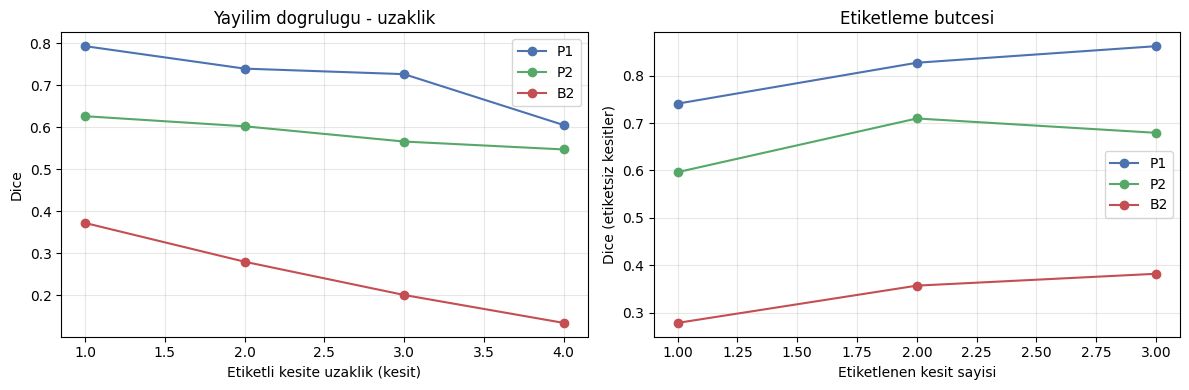

frame loading (JPEG): 100%|██████████| 5/5 [00:00<00:00, 24.45it/s]
/content/sam2/sam2/sam2_video_predictor.py:786: UserWarning: cannot import name '_C' from 'sam2' (/content/sam2/sam2/__init__.py)

Skipping the post-processing step due to the error above. You can still use SAM 2 and it's OK to ignore the error above, although some post-processing functionality may be limited (which doesn't affect the results in most cases; see https://github.com/facebookresearch/sam2/blob/main/INSTALL.md).
  pred_masks_gpu = fill_holes_in_mask_scores(
propagate in video: 100%|██████████| 5/5 [00:01<00:00,  4.06it/s]
propagate in video: 0it [00:00, ?it/s]


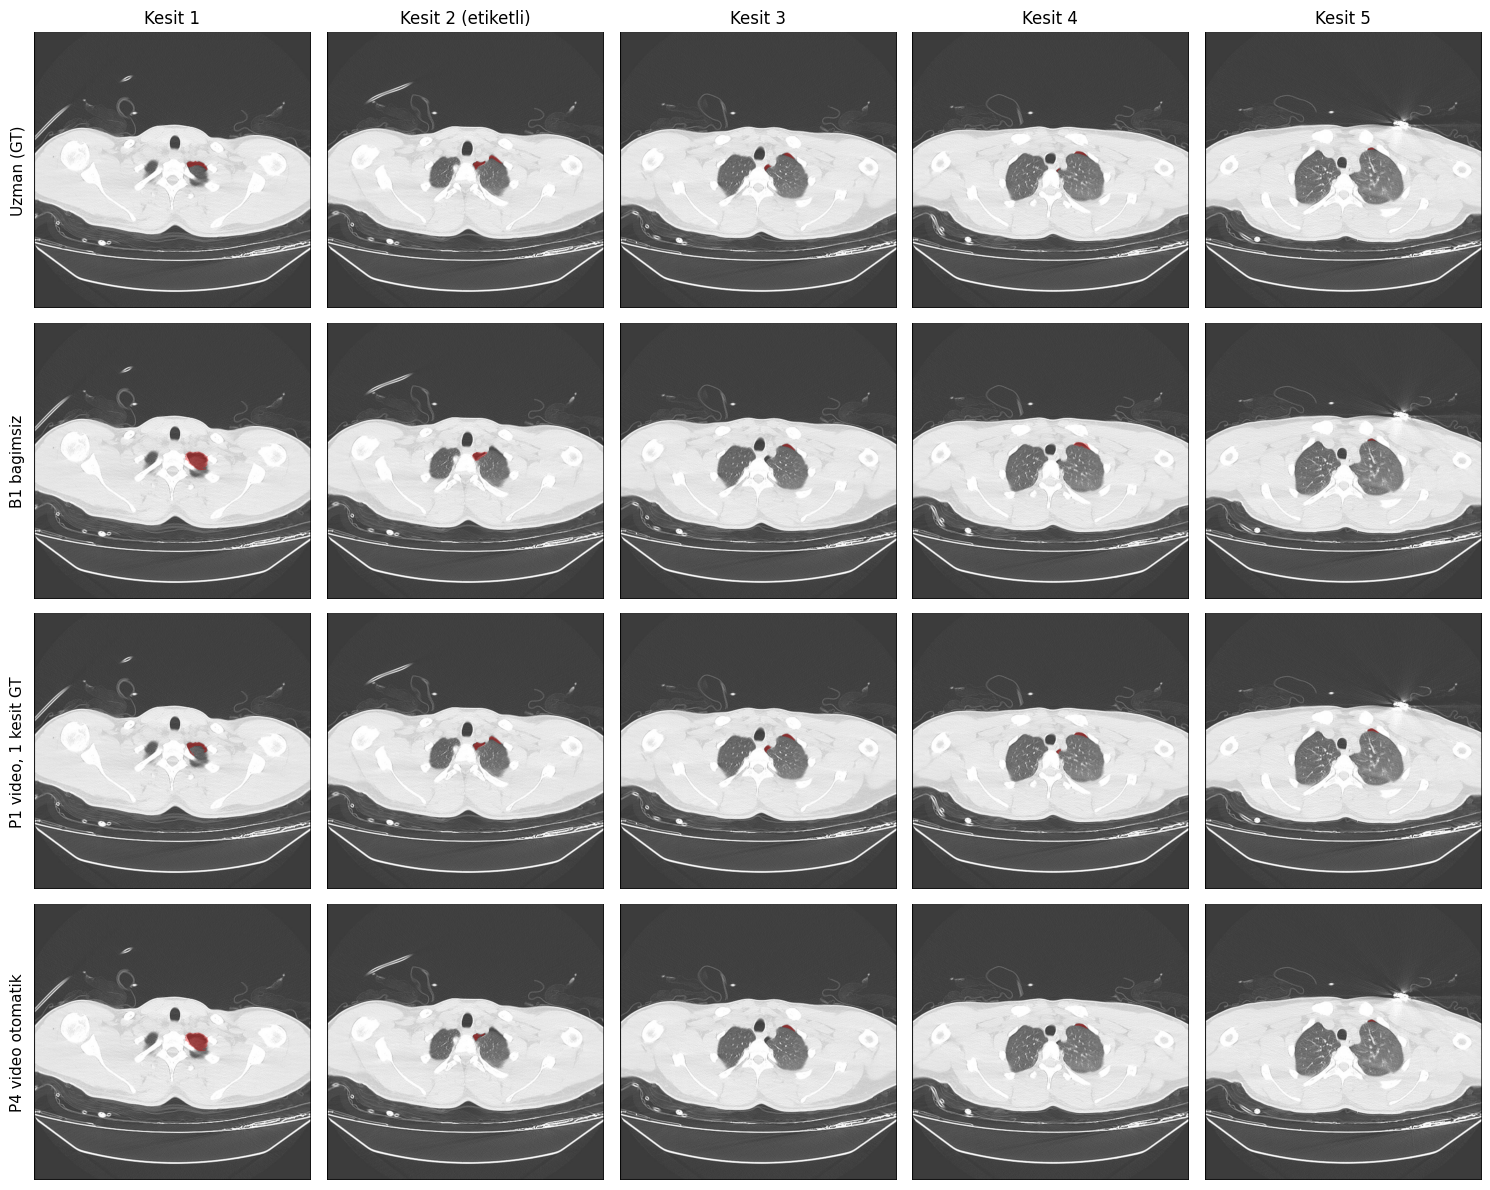

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for y, c in [('P1_b1', '#4C72B0'), ('P2_b1', '#55A868'), ('B2_b1', '#C44E52')]:
    g = res[(res.yontem == y) & ~res.etiketli_kesit & res.gt_pos].groupby('uzaklik').dice.mean()
    ax[0].plot(g.index, g.values, 'o-', label=y.split('_')[0], color=c)
ax[0].set_xlabel('Etiketli kesite uzaklik (kesit)'); ax[0].set_ylabel('Dice'); ax[0].legend(); ax[0].grid(alpha=.3)
ax[0].set_title('Yayilim dogrulugu - uzaklik')
cc = tabloC.reset_index()
for y, c in [('P1', '#4C72B0'), ('P2', '#55A868'), ('B2', '#C44E52')]:
    g = cc[cc.yontem == y]
    ax[1].plot(g.butce, g.Dice, 'o-', label=y, color=c)
ax[1].set_xlabel('Etiketlenen kesit sayisi'); ax[1].set_ylabel('Dice (etiketsiz kesitler)'); ax[1].legend(); ax[1].grid(alpha=.3)
ax[1].set_title('Etiketleme butcesi')
plt.tight_layout(); plt.savefig(f'{OUT_DIR}/SEKIL_uzaklik_butce.png', dpi=300); plt.show()

# Ornek hasta: kesit serisi boyunca GT / B1 / P1 / P4
ornek_pid = res[(res.yontem == 'P1_b1') & res.gt_pos].groupby('patient_id').size().idxmax()
s = hasta_calistir(ornek_pid, butceler=(1,), taus=(EN_IYI_TAU,))
imgs, gts = VERI[ornek_pid]['imgs'], VERI[ornek_pid]['gts']
satir = [('Uzman (GT)', gts), ('B1 bagimsiz', s['B1']), ('P1 video, 1 kesit GT', s['P1_b1']), ('P4 video otomatik', s[f'P4_t{EN_IYI_TAU}'])]
fig, ax = plt.subplots(len(satir), len(imgs), figsize=(3 * len(imgs), 3 * len(satir)))
for r_, (t, ms) in enumerate(satir):
    for c_ in range(len(imgs)):
        ax[r_, c_].imshow(po.make_overlay(imgs[c_], ms[c_])); ax[r_, c_].axis('off')
        if r_ == 0:
            ax[r_, c_].set_title(f'Kesit {c_ + 1}' + (' (etiketli)' if c_ in s['_anahtar'].get(1, []) else ''))
    ax[r_, 0].text(-30, imgs[0].shape[0] / 2, t, rotation=90, va='center', ha='right', fontsize=11)
plt.tight_layout(); plt.savefig(f'{OUT_DIR}/SEKIL_ornek_hasta_seri.png', dpi=200); plt.show()